# 07 - Tier 3: CNN + GRU
Trains `QuantTimeSeriesNet` (Conv1d -> GELU -> Dropout -> GRU -> Dropout -> Linear) on the same Train/Val/Test splits as Ridge/XGBoost (notebook 02), using zero-copy sliding windows (`torch.Tensor.unfold`). Loss is selectable (`huber` by default, per spec). Progress updates a single in-place widget line per epoch instead of flooding output.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.models import CNNGRUModel, RidgeModel, XGBoostModel
from src.metrics import pearson_ic, spearman_ic, hit_rate
from src.progress import NotebookProgress
from src.visualization import plot_price_with_signal, plot_holding_windows

DATA_DIR = PROJECT_ROOT / 'data'
SPLIT_DIR = DATA_DIR / 'splits'
MODEL_DIR = DATA_DIR / 'models'

torch.manual_seed(0)

## Load the same splits used by Ridge/XGBoost
These are already scaled (fit on Train only) from notebook 02.

In [2]:
train = pd.read_parquet(SPLIT_DIR / 'train.parquet')
val = pd.read_parquet(SPLIT_DIR / 'val.parquet')
test = pd.read_parquet(SPLIT_DIR / 'test.parquet')

target_col = [c for c in train.columns if c.startswith('fwd_log_return')][0]
feature_cols = [c for c in train.columns if c != target_col]
HORIZON = int(target_col.rsplit('_', 1)[1])

X_train, y_train = train[feature_cols], train[target_col]
X_val, y_val = val[feature_cols], val[target_col]
X_test, y_test = test[feature_cols], test[target_col]
X_train.shape, X_val.shape, X_test.shape

((3237, 12), (427, 12), (891, 12))

## Configure the model
`SEQ_LEN` must match the embargo gap used in notebook 02 (it was sized as `SEQ_LEN + HORIZON`). `CNN_LOSS` picks the training objective: `'huber'` (spec default), `'mse'`, or `'mae'`.

In [3]:
SEQ_LEN = 30
CNN_LOSS = 'huber'

cnn_model = CNNGRUModel(
    n_features=len(feature_cols),
    seq_len=SEQ_LEN,
    loss=CNN_LOSS,
    lr=1e-3,
    weight_decay=1e-2,
    max_epochs=50,
    patience=8,
    batch_size=256,
)
print(cnn_model.name, '| device:', cnn_model.device)

CNN+GRU(loss=huber) | device: cpu


## Train
Checkpointing keeps the weights from the epoch with the best validation Spearman IC (not lowest loss), per spec.

In [4]:
progress = NotebookProgress(total=cnn_model.max_epochs, description='CNN+GRU')
cnn_model.fit(X_train, y_train, X_val, y_val, progress=progress)
progress.close(f'best_val_spearman_ic={cnn_model.best_val_ic:.4f}')

## Evaluate on the held-out Test set
The first `SEQ_LEN - 1` test rows have no full window yet, so align `y_test` accordingly.

In [5]:
pred = cnn_model.predict(X_test)
y_test_aligned = y_test.iloc[SEQ_LEN - 1:]
assert len(pred) == len(y_test_aligned)

cnn_row = {
    'model': cnn_model.name,
    'pearson_ic': pearson_ic(y_test_aligned.values, pred),
    'spearman_ic': spearman_ic(y_test_aligned.values, pred),
    'hit_rate': hit_rate(y_test_aligned.values, pred),
}
cnn_row

{'model': 'CNN+GRU(loss=huber)',
 'pearson_ic': 0.08011680192265684,
 'spearman_ic': 0.06849429507648916,
 'hit_rate': 0.5266821345707656}

## Compare against Ridge and XGBoost (from notebook 04)

In [6]:
prior_results = pd.read_parquet(MODEL_DIR / 'results.parquet').reset_index()
all_results = pd.concat([prior_results, pd.DataFrame([cnn_row])], ignore_index=True).set_index('model')
all_results

,pearson_ic,spearman_ic,hit_rate
model,,,
Ridge(alpha=1.0),0.041645,-0.040118,0.471380
XGBoost(loss=huber),0.060334,0.106790,0.544332
CNN+GRU(loss=huber),0.080117,0.068494,0.526682


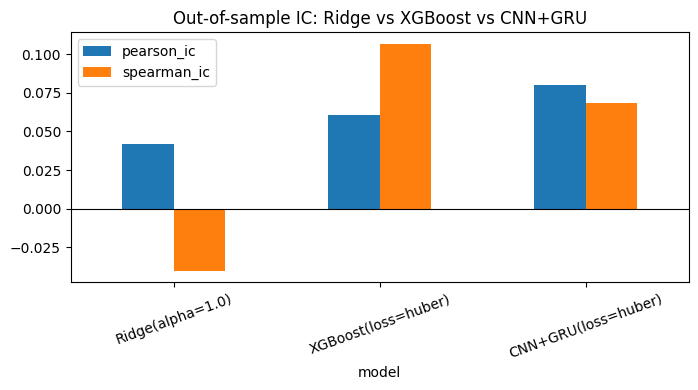

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
all_results[['pearson_ic', 'spearman_ic']].plot.bar(ax=ax)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Out-of-sample IC: Ridge vs XGBoost vs CNN+GRU')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Signal + holding window on the price chart (same view as notebook 05)

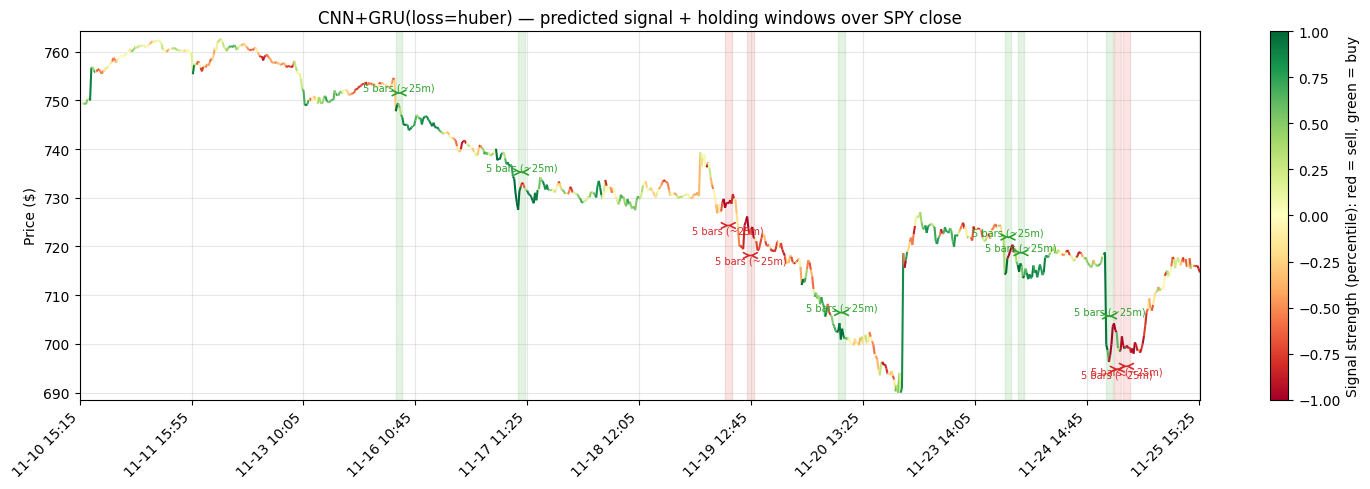

In [8]:
raw_close = pd.read_parquet(DATA_DIR / 'raw_close.parquet')['close']
price_test_aligned = raw_close.loc[y_test_aligned.index]

fig, ax = plt.subplots(figsize=(15, 5))
plot_price_with_signal(price_test_aligned.index, price_test_aligned, pred,
                        title=f'{cnn_model.name} — predicted signal + holding windows over SPY close', ax=ax)
plot_holding_windows(ax, price_test_aligned, pred, horizon=HORIZON,
                      index=price_test_aligned.index, max_windows=10, strength_threshold=0.85)
plt.tight_layout()
plt.show()

## Persist

In [9]:
cnn_model.to_cpu()
joblib.dump(cnn_model, MODEL_DIR / 'cnn_gru.joblib')
all_results.to_parquet(MODEL_DIR / 'results.parquet')
print('Saved cnn_gru.joblib and updated results.parquet')

Saved cnn_gru.joblib and updated results.parquet
